# Stage 4 — MobileViT presentation artifacts

This notebook evaluates the best Stage 3 checkpoint once and creates the four presentation artifacts: model flow, training curves, confusion matrix, and representative predictions.

> **Required label:** preliminary pipeline validation only; tile-level splitting may contain parent-photograph leakage and is not a Phase 3 result.

In [51]:
%pip install -q timm scikit-learn matplotlib

## 1. Load Stage 2 and Stage 3 artifacts

Keep the Stage 3 Colab runtime alive. If it was reset, rerun Stages 2 and 3 because `/content` storage is temporary.

In [52]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
from PIL import Image
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
import timm
from timm.data import create_transform
import torch
from torch.utils.data import DataLoader, Dataset

AUDIT_DIR = Path("outputs/sdnet2018_audit")
TRAINING_DIR = Path("outputs/mobilevit_xs/development_training")
OUTPUT_DIR = Path("outputs/mobilevit_xs/presentation")
MANIFEST_PATH = AUDIT_DIR / "development_manifest.csv"
STAGE_TWO_SUMMARY_PATH = AUDIT_DIR / "stage_two_summary.json"
CHECKPOINT_PATH = TRAINING_DIR / "best_mobilevit_xs.pt"
HISTORY_PATH = TRAINING_DIR / "history.json"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [MANIFEST_PATH, STAGE_TWO_SUMMARY_PATH, CHECKPOINT_PATH, HISTORY_PATH]
missing = [str(path) for path in required_paths if not path.exists()]
if missing:
    raise FileNotFoundError(f"Missing earlier-stage artifacts: {missing}")

stage_two_summary = json.loads(STAGE_TWO_SUMMARY_PATH.read_text(encoding="utf-8"))
history = json.loads(HISTORY_PATH.read_text(encoding="utf-8"))
dataset_root = Path(stage_two_summary["dataset_root"])
with MANIFEST_PATH.open(newline="", encoding="utf-8") as stream:
    validation_rows = [
        row for row in csv.DictReader(stream) if row["split"] == "dev_validation"
    ]

if not dataset_root.exists():
    raise FileNotFoundError(f"Dataset root no longer exists: {dataset_root}")
if not validation_rows:
    raise ValueError("The validation partition is empty.")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print({"device": str(DEVICE), "validation_images": len(validation_rows), "output_dir": str(OUTPUT_DIR.resolve())})

{'device': 'cuda', 'validation_images': 720, 'output_dir': '/content/outputs/mobilevit_xs/presentation'}


## 2. Restore the best checkpoint and evaluate once

In [53]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model = timm.create_model(checkpoint["model_name"], pretrained=False, num_classes=1)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE).eval()
validation_transform = create_transform(**checkpoint["data_config"], is_training=False)

class ValidationDataset(Dataset):
    def __len__(self):
        return len(validation_rows)

    def __getitem__(self, index):
        row = validation_rows[index]
        with Image.open(dataset_root / row["path"]) as image:
            tensor = validation_transform(image.convert("RGB"))
        return tensor, int(row["label"]), row["path"], row["surface"]

loader = DataLoader(
    ValidationDataset(), batch_size=64, shuffle=False, num_workers=2,
    pin_memory=DEVICE.type == "cuda",
)

prediction_rows = []
with torch.inference_mode():
    for images, labels, paths, surfaces in loader:
        probabilities = torch.sigmoid(model(images.to(DEVICE)).squeeze(1)).cpu().numpy()
        for path, surface, label, probability in zip(paths, surfaces, labels.numpy(), probabilities):
            prediction_rows.append({
                "path": path, "surface": surface, "label": int(label),
                "probability": float(probability),
                "prediction": int(probability >= 0.5),
            })

labels = np.array([row["label"] for row in prediction_rows])
probabilities = np.array([row["probability"] for row in prediction_rows])
predictions = np.array([row["prediction"] for row in prediction_rows])
matrix = confusion_matrix(labels, predictions)
metrics = {
    "f1": f1_score(labels, predictions),
    "recall": recall_score(labels, predictions),
    "precision": precision_score(labels, predictions),
    "balanced_accuracy": balanced_accuracy_score(labels, predictions),
    "pr_auc": average_precision_score(labels, probabilities),
    "roc_auc": roc_auc_score(labels, probabilities),
    "confusion_matrix": matrix.tolist(),
    "threshold": 0.5,
    "split_basis": "tile_development_only",
}

with (OUTPUT_DIR / "validation_predictions.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=prediction_rows[0].keys())
    writer.writeheader()
    writer.writerows(prediction_rows)
(OUTPUT_DIR / "validation_metrics.json").write_text(
    json.dumps(metrics, indent=2) + "\n", encoding="utf-8"
)

comparison_keys = ["f1", "recall", "precision", "balanced_accuracy", "pr_auc", "roc_auc"]
metric_deltas = {
    key: abs(metrics[key] - checkpoint["validation_metrics"][key])
    for key in comparison_keys
}
print(json.dumps(metrics, indent=2))
print("Largest difference from saved Stage 3 metrics:", max(metric_deltas.values()))
if max(metric_deltas.values()) > 1e-4:
    print("WARNING: evaluation differs from the saved checkpoint metrics; inspect the runtime and inputs.")
print("Saved per-image predictions and metrics.")

{
  "f1": 0.808695652173913,
  "recall": 0.775,
  "precision": 0.8454545454545455,
  "balanced_accuracy": 0.8166666666666667,
  "pr_auc": 0.9195562817938359,
  "roc_auc": 0.9014506172839507,
  "confusion_matrix": [
    [
      309,
      51
    ],
    [
      81,
      279
    ]
  ],
  "threshold": 0.5,
  "split_basis": "tile_development_only"
}
Largest difference from saved Stage 3 metrics: 0.00022860558086001959
Saved per-image predictions and metrics.


## 3. Training and validation curves

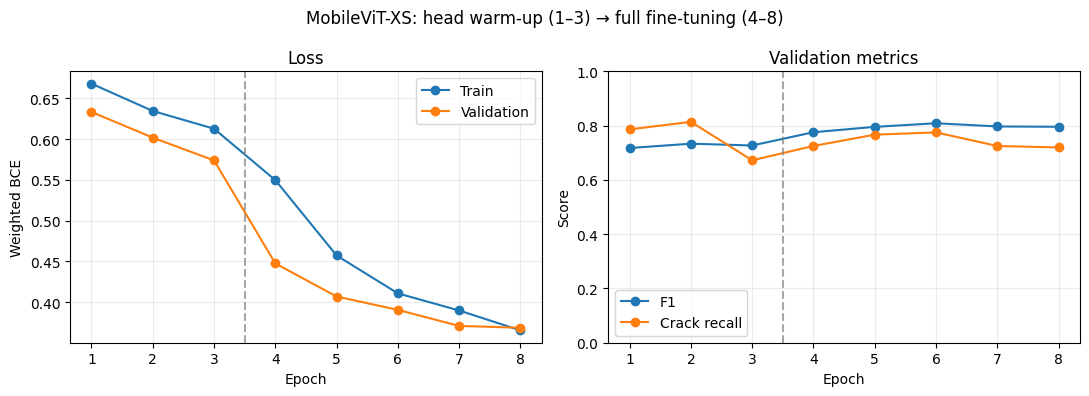

Saved /content/outputs/mobilevit_xs/presentation/training_curves.png


In [54]:
epochs = np.arange(1, len(history) + 1)
train_loss = [row["train_loss"] for row in history]
validation_loss = [row["validation_loss"] for row in history]
validation_f1 = [row["validation_metrics"]["f1"] for row in history]
validation_recall = [row["validation_metrics"]["recall"] for row in history]

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, train_loss, marker="o", label="Train")
axes[0].plot(epochs, validation_loss, marker="o", label="Validation")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Weighted BCE")
axes[0].legend()
axes[1].plot(epochs, validation_f1, marker="o", label="F1")
axes[1].plot(epochs, validation_recall, marker="o", label="Crack recall")
axes[1].set(title="Validation metrics", xlabel="Epoch", ylabel="Score", ylim=(0, 1))
axes[1].legend()
for axis in axes:
    axis.axvline(3.5, color="gray", linestyle="--", alpha=0.7)
    axis.grid(alpha=0.25)
figure.suptitle("MobileViT-XS: head warm-up (1–3) → full fine-tuning (4–8)")
figure.tight_layout()
curve_path = OUTPUT_DIR / "training_curves.png"
figure.savefig(curve_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved", curve_path.resolve())

## 4. Validation confusion matrix

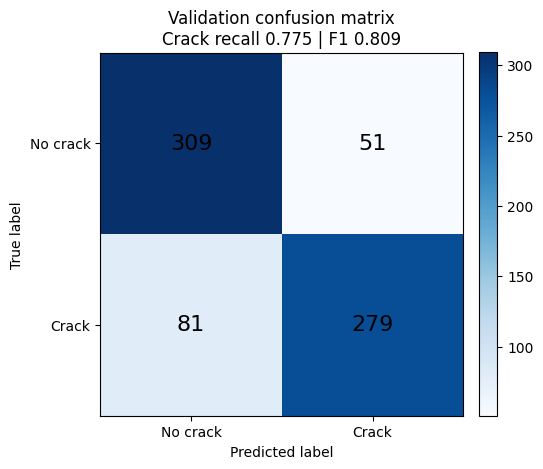

Saved /content/outputs/mobilevit_xs/presentation/confusion_matrix.png


In [55]:
figure, axis = plt.subplots(figsize=(5.4, 4.8))
image = axis.imshow(matrix, cmap="Blues")
for row in range(2):
    for column in range(2):
        axis.text(column, row, f"{matrix[row, column]:,}", ha="center", va="center", fontsize=16)
axis.set(
    xticks=[0, 1], yticks=[0, 1],
    xticklabels=["No crack", "Crack"], yticklabels=["No crack", "Crack"],
    xlabel="Predicted label", ylabel="True label",
    title=f"Validation confusion matrix\nCrack recall {metrics['recall']:.3f} | F1 {metrics['f1']:.3f}",
)
figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
figure.tight_layout()
confusion_path = OUTPUT_DIR / "confusion_matrix.png"
figure.savefig(confusion_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved", confusion_path.resolve())

## 5. Correct predictions, false positives, and false negatives

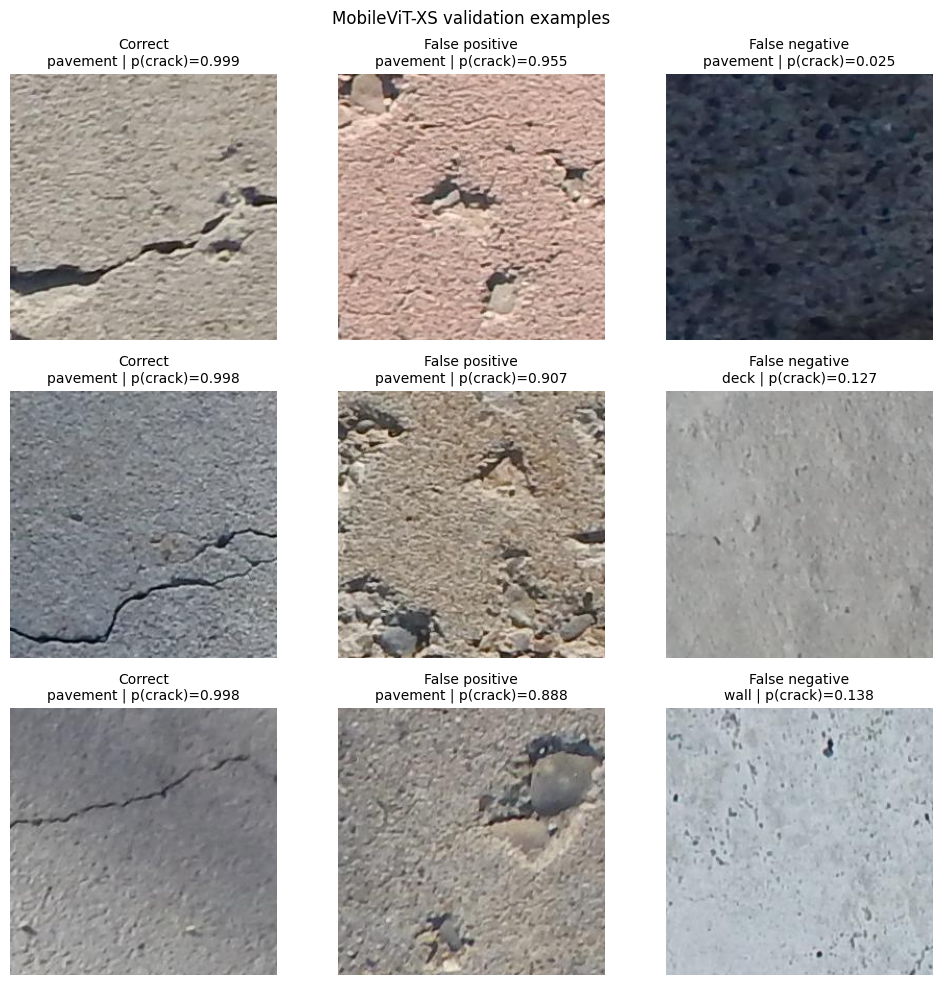

Saved /content/outputs/mobilevit_xs/presentation/prediction_examples.png


In [56]:
correct = sorted(
    (row for row in prediction_rows if row["label"] == row["prediction"]),
    key=lambda row: abs(row["probability"] - 0.5), reverse=True,
)
false_positives = sorted(
    (row for row in prediction_rows if row["label"] == 0 and row["prediction"] == 1),
    key=lambda row: row["probability"], reverse=True,
)
false_negatives = sorted(
    (row for row in prediction_rows if row["label"] == 1 and row["prediction"] == 0),
    key=lambda row: row["probability"],
)
groups = [("Correct", correct), ("False positive", false_positives), ("False negative", false_negatives)]

figure, axes = plt.subplots(3, 3, figsize=(10, 10))
for column, (group_name, group_rows) in enumerate(groups):
    for row_index, axis in enumerate(axes[:, column]):
        if row_index >= len(group_rows):
            axis.axis("off")
            continue
        item = group_rows[row_index]
        with Image.open(dataset_root / item["path"]) as source_image:
            axis.imshow(source_image.convert("RGB"))
        axis.set_title(
            f"{group_name}\n{item['surface']} | p(crack)={item['probability']:.3f}",
            fontsize=10,
        )
        axis.axis("off")
figure.suptitle("MobileViT-XS validation examples")
figure.tight_layout()
examples_path = OUTPUT_DIR / "prediction_examples.png"
figure.savefig(examples_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved", examples_path.resolve())

## 6. MobileViT feature-flow diagram

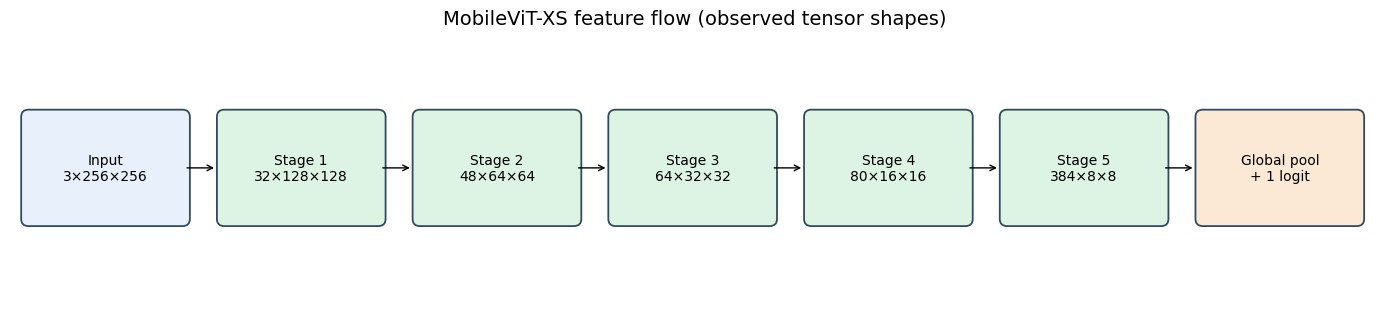

Feature shapes: [[1, 32, 128, 128], [1, 48, 64, 64], [1, 64, 32, 32], [1, 80, 16, 16], [1, 384, 8, 8]]
Saved /content/outputs/mobilevit_xs/presentation/mobilevit_feature_flow.png


In [57]:
feature_model = timm.create_model(checkpoint["model_name"], pretrained=False, features_only=True).to(DEVICE).eval()
dummy = torch.zeros(1, *checkpoint["data_config"]["input_size"], device=DEVICE)
with torch.inference_mode():
    feature_shapes = [list(feature.shape) for feature in feature_model(dummy)]
del feature_model, dummy

flow_labels = ["Input\n3×256×256"] + [
    f"Stage {index}\n{shape[1]}×{shape[2]}×{shape[3]}"
    for index, shape in enumerate(feature_shapes, start=1)
] + ["Global pool\n+ 1 logit"]
colors = ["#E8F1FB"] + ["#DDF3E4"] * len(feature_shapes) + ["#FBE8D5"]
figure, axis = plt.subplots(figsize=(14, 3.2))
axis.set_xlim(0, len(flow_labels) * 2.1)
axis.set_ylim(0, 3)
axis.axis("off")
for index, (label, color) in enumerate(zip(flow_labels, colors)):
    x = index * 2.1 + 0.2
    box = FancyBboxPatch(
        (x, 0.9), 1.65, 1.15, boxstyle="round,pad=0.08",
        facecolor=color, edgecolor="#34495E", linewidth=1.3,
    )
    axis.add_patch(box)
    axis.text(x + 0.825, 1.475, label, ha="center", va="center", fontsize=10)
    if index < len(flow_labels) - 1:
        axis.annotate("", xy=(x + 2.02, 1.475), xytext=(x + 1.67, 1.475), arrowprops={"arrowstyle": "->"})
axis.set_title("MobileViT-XS feature flow (observed tensor shapes)", fontsize=14)
figure.tight_layout()
flow_path = OUTPUT_DIR / "mobilevit_feature_flow.png"
figure.savefig(flow_path, dpi=180, bbox_inches="tight")
plt.show()
print("Feature shapes:", feature_shapes)
print("Saved", flow_path.resolve())

## 7. Save the presentation summary

In [58]:
summary = {
    "model": checkpoint["model_name"],
    "checkpoint_phase": checkpoint["phase"],
    "checkpoint_epoch": checkpoint["epoch"],
    "validation_images": len(validation_rows),
    "metrics": metrics,
    "feature_shapes": feature_shapes,
    "artifacts": {
        "feature_flow": str(flow_path.resolve()),
        "training_curves": str(curve_path.resolve()),
        "confusion_matrix": str(confusion_path.resolve()),
        "prediction_examples": str(examples_path.resolve()),
        "predictions": str((OUTPUT_DIR / "validation_predictions.csv").resolve()),
    },
    "limitation": "Preliminary pipeline validation only; tile-level splitting may contain parent-photograph leakage and is not a Phase 3 result.",
}
summary_path = OUTPUT_DIR / "presentation_summary.json"
summary_path.write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")

for name, path in summary["artifacts"].items():
    assert Path(path).exists(), f"Missing {name}: {path}"
print(json.dumps(summary, indent=2))
print("Stage 4 complete. Saved", summary_path.resolve())

{
  "model": "mobilevit_xs.cvnets_in1k",
  "checkpoint_phase": "full",
  "checkpoint_epoch": 3,
  "validation_images": 720,
  "metrics": {
    "f1": 0.808695652173913,
    "recall": 0.775,
    "precision": 0.8454545454545455,
    "balanced_accuracy": 0.8166666666666667,
    "pr_auc": 0.9195562817938359,
    "roc_auc": 0.9014506172839507,
    "confusion_matrix": [
      [
        309,
        51
      ],
      [
        81,
        279
      ]
    ],
    "threshold": 0.5,
    "split_basis": "tile_development_only"
  },
  "feature_shapes": [
    [
      1,
      32,
      128,
      128
    ],
    [
      1,
      48,
      64,
      64
    ],
    [
      1,
      64,
      32,
      32
    ],
    [
      1,
      80,
      16,
      16
    ],
    [
      1,
      384,
      8,
      8
    ]
  ],
  "artifacts": {
    "feature_flow": "/content/outputs/mobilevit_xs/presentation/mobilevit_feature_flow.png",
    "training_curves": "/content/outputs/mobilevit_xs/presentation/training_curves.p

## Stage 4 exit criterion

Stage 4 is complete when all four PNG figures render, their files and per-image predictions are saved, the evaluation metrics match the best Stage 3 checkpoint, and every presentation use includes the preliminary-results limitation.